# Лабораторная работа 2 — мультимодальные модели для мониторинга отзывов

**Автор:** Яковенко Арина, ПМ23-4.  
**Тема ВКР:** «Исследование влияния качества и дрейфа данных на продуктовые метрики».  
**Среда:** Google Colab, GPU Tesla T4.

**Вопрос.** Улучшают ли фотография товара и история его оценок обнаружение негативного отзыва по сравнению с одним текстом на позднем временном периоде? Отрицательный отзыв (1–2 звезды) служит *прокси жалобы*, положительный (4–5) — прокси отсутствия жалобы. Оценки в 3 звезды исключаются только из целевой переменной, но остаются в доступной на момент публикации истории товара. Это не ручная разметка жалоб.

Объект имеет три модальности: текущие заголовок и текст отзыва; числовой ряд прежних оценок того же `parent_asin`; главное изображение товара из метаданных. Текст и прежние оценки привязаны к UTC timestamp; все числовые признаки рассчитываются строго по отзывам с более ранним временем. Изображения в метаданных являются снимком на момент сбора датасета, дата их появления неизвестна. Поэтому эксперимент с фото — ретроспективный и не доказывает пригодность для исторического online-прогноза без отдельного архива версий карточек товара.

Сравниваются 8 схем: текст, числа, изображение; три попарных ранних слияния; раннее слияние всех трёх; позднее слияние вероятностей. Гипотеза о пользе усложнения принимается только если лучшая схема fusion выбрана на validation и её прирост к лучшему одномодальному baseline на test положителен, 95% кластерный bootstrap-интервал разности не включает ноль и paired permutation test даёт p < 0,05. В противном случае сохраняется лучший одномодальный baseline.

**Источники данных:** [Amazon Reviews 2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023), таблицы `raw_review_All_Beauty` и `raw_meta_All_Beauty`, ревизия `749931181c9cdd70bfa6408d8fe8b4ddd6107248`. Загрузка выполняется в самом Colab. Исходные отзывы и фотографии не публикуются в артефактах.

## 1. Исследовательский обзор

Матрица ниже сопоставляет источники по модальностям, способу слияния, задаче и доступности кода. Статьи о больших архитектурах помогают выбрать принципы, но в эксперименте на T4 используются замороженный ResNet-18 и прозрачные линейные классификаторы: задача лабораторной — измерить вклад модальностей при одном протоколе, а не воспроизвести обучение моделей из статей.

| Источник | Модальности и fusion | Задача / данные / метрика | Код |
|---|---|---|---|
| [Baltrušaitis et al., 2017](https://arxiv.org/abs/1705.09406) | Таксономия представления, выравнивания и fusion | Обзор мультимодального ML; собственного benchmark нет | Не применимо |
| [Radford et al., CLIP, 2021](https://arxiv.org/abs/2103.00020) | Контрастивное выравнивание текста и изображения | Zero-shot vision, >30 наборов, accuracy | [Открыт](https://github.com/openai/CLIP) |
| [Dosovitskiy et al., ViT, 2021](https://arxiv.org/abs/2010.11929) | Патчи изображения, self-attention | Классификация изображений, ImageNet/CIFAR/VTAB, accuracy | [Открыт](https://github.com/google-research/vision_transformer) |
| [Li et al., BLIP-2, 2023](https://arxiv.org/abs/2301.12597) | Визуальный encoder + Q-Former + LLM | VQA/captioning, accuracy/CIDEr | [Открыт](https://github.com/salesforce/LAVIS) |
| [Tsai et al., MuLT, 2019](https://arxiv.org/abs/1906.00295) | Cross-modal attention для невыравненных последовательностей | Мультимодальная тональность, CMU-MOSEI, accuracy/F1 | [Открыт](https://github.com/yaohungt/Multimodal-Transformer) |
| [Arevalo et al., GMU, 2017](https://arxiv.org/abs/1702.01992) | Обучаемый гейт модальностей | Fusion, классификация, accuracy | Доступность реализации надо проверять |
| [Neverova et al., ModDrop, 2015](https://arxiv.org/abs/1501.00102) | Случайное удаление каналов при обучении | Распознавание жестов при пропаже сигнала, recognition rate | Доступность реализации надо проверять |
| [Nie et al., PatchTST, 2023](https://arxiv.org/abs/2211.14730) | Патчи временного ряда, Transformer | Долгосрочный прогноз, MSE/MAE | [Открыт](https://github.com/yuqinie98/PatchTST) |
| [Wu et al., TimesNet, 2023](https://arxiv.org/abs/2210.02186) | 2D-представление периодов ряда | Прогноз/классификация рядов, MSE/MAE/accuracy | [Открыт](https://github.com/thuml/TimesNet) |
| [Devlin et al., BERT, 2019](https://arxiv.org/abs/1810.04805) | Контекстный текстовый encoder | NLP benchmark, F1/accuracy | [Открыт](https://github.com/google-research/bert) |
| [Hou et al., BLaIR / Amazon Reviews 2023, 2024](https://arxiv.org/abs/2403.03952) | Связь текста и товара | Retrieval/recommendation на Amazon Reviews, retrieval metrics | [Данные открыты](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023) |
| [Guo et al., 2017](https://arxiv.org/abs/1706.04599) | Калибровка вероятностей | ECE/Brier/NLL для классификации | Доступность реализации надо проверять |

**Разрыв.** В работах о fusion часто сравнивают архитектуры на готовых benchmark и не проверяют, дает ли фото *дополнительный* выигрыш для прокси жалобы после честного временного split и учёта затрат. Здесь отдельно фиксируются пропуски модальностей, временная доступность признаков и продуктовые ошибки на 1000 отзывов.

In [1]:
import os, time, json, math, hashlib, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
from IPython.display import display
from huggingface_hub import hf_hub_download

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), "В Colab выберите Среда выполнения → Сменить среду выполнения → GPU T4"
GPU = torch.cuda.get_device_name(0)
assert "T4" in GPU, f"Требуется T4, обнаружено: {GPU}"
print("GPU:", GPU, "| PyTorch:", torch.__version__, "| Python:", os.sys.version.split()[0])

GPU: Tesla T4 | PyTorch: 2.11.0+cu130 | Python: 3.13.15


## 2. Паспорт данных и синхронизация

Таблица отзывов содержит `rating`, `title`, `text`, `timestamp` (Unix milliseconds), `parent_asin` и `user_id`. Таблица метаданных содержит `parent_asin`, `images` и описание товара. Соединение выполняется по `parent_asin`; дубликаты ключа метаданных удаляются, а число удалённых строк записывается. В числовую модальность не попадают `rating` текущего отзыва, `average_rating` из метаданных, `helpful_vote` и другие поля, которые могли быть обновлены после публикации. История одного товара может встречаться в разных временных частях: так устроен сценарий мониторинга известного товара; близкие точные дубликаты текста удаляются до разбиения.

In [2]:
import pyarrow.parquet as pq
REPO = "McAuley-Lab/Amazon-Reviews-2023"
REV = "749931181c9cdd70bfa6408d8fe8b4ddd6107248"
review_name = "raw_review_All_Beauty/full-00000-of-00001.parquet"
meta_name = "raw_meta_All_Beauty/full-00000-of-00001.parquet"
review_path = hf_hub_download(REPO, review_name, repo_type="dataset", revision=REV)
meta_path = hf_hub_download(REPO, meta_name, repo_type="dataset", revision=REV)
rv = pq.read_table(review_path, columns=["rating","title","text","timestamp","parent_asin","user_id"]).to_pandas()
mt = pq.read_table(meta_path, columns=["parent_asin","images","title","main_category"]).to_pandas()
print("Отзывы:", len(rv), "Товары в метаданных:", len(mt))
print("Объём parquet, МБ:", round(os.path.getsize(review_path)/1e6,1), round(os.path.getsize(meta_path)/1e6,1))
print("Распределение рейтинга:", rv.rating.value_counts(dropna=False).sort_index().to_dict())
print("Пропуски в отзывах:"); display(rv.isna().sum().to_frame("n"))
print("Дата, UTC:", pd.to_datetime(rv.timestamp.min(),unit="ms",utc=True), "—", pd.to_datetime(rv.timestamp.max(),unit="ms",utc=True))

raw_review_All_Beauty/full-00000-of-0000(…): reconstructing file:   0%|          |  0.00B /  139MB            

raw_review_All_Beauty/full-00000-of-0000(…): downloading bytes:           |  0.00B            

raw_meta_All_Beauty/full-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 60.1MB            

raw_meta_All_Beauty/full-00000-of-00001.(…): downloading bytes:           |  0.00B            

Отзывы: 701528 Товары в метаданных: 112590
Объём parquet, МБ: 139.1 60.1
Распределение рейтинга: {1.0: 102080, 2.0: 43034, 3.0: 56307, 4.0: 79381, 5.0: 420726}
Пропуски в отзывах:


,n
rating,0
title,0
text,0
timestamp,0
parent_asin,0
user_id,0


Дата, UTC: 2000-11-01 04:24:18+00:00 — 2023-09-09 00:39:36.666000+00:00


In [3]:
def first_image_url(value):
    if not isinstance(value, dict): return None
    for key in ("large", "hi_res"):
        for url in value.get(key, []):
            if isinstance(url, str) and url.startswith("https://"): return url
    return None

meta_dups = int(mt.duplicated("parent_asin").sum())
mt = mt.drop_duplicates("parent_asin", keep="first").copy()
mt["image_url"] = mt.images.map(first_image_url)
rv = rv.dropna(subset=["parent_asin","timestamp","rating"]).copy()
rv["timestamp"] = pd.to_numeric(rv.timestamp, errors="coerce")
rv = rv.dropna(subset=["timestamp"]).sort_values(["parent_asin","timestamp","user_id"],kind="mergesort").reset_index(drop=True)
rv["date_utc"] = pd.to_datetime(rv.timestamp, unit="ms", utc=True)
rv["review_text"] = (rv.title.fillna("").astype(str) + " " + rv.text.fillna("").astype(str)).str.strip()
g = rv.groupby("parent_asin", sort=False)
rv["prior_n"] = g.cumcount()
rv["prior_sum"] = g.rating.cumsum() - rv.rating
rv["prior_mean"] = rv.prior_sum / rv.prior_n.replace(0,np.nan)
rv["prior_sqsum"] = (rv.rating.pow(2).groupby(rv.parent_asin).cumsum() - rv.rating.pow(2))
rv["prior_std"] = np.sqrt((rv.prior_sqsum/rv.prior_n.replace(0,np.nan) - rv.prior_mean.pow(2)).clip(lower=0))
rv["is_neg"] = rv.rating.le(2).astype(int)
rv["prior_neg_rate"] = (rv.is_neg.groupby(rv.parent_asin).cumsum()-rv.is_neg) / rv.prior_n.replace(0,np.nan)
rv["days_since_prev"] = (rv.timestamp-g.timestamp.shift(1))/86_400_000
for k in range(1,6): rv[f"lag{k}"] = g.rating.shift(k)
rv["history_age_days"] = (rv.timestamp-g.timestamp.transform("min"))/86_400_000
rv["prior_n_log"] = np.log1p(rv.prior_n)

audit = {"raw_reviews":int(len(rv)), "raw_metadata":int(len(mt)+meta_dups),
         "duplicate_metadata_keys":meta_dups, "missing_meta_images":int(mt.image_url.isna().sum())}
eligible = rv.loc[(rv.prior_n>=3)&rv.rating.isin([1,2,4,5])&(rv.review_text.str.len()>=15)].copy()
audit["eligible_before_dedup"] = int(len(eligible))
eligible["text_key"] = eligible.review_text.str.lower().str.replace(r"\s+"," ",regex=True).str.strip()
eligible = eligible.sort_values("timestamp").drop_duplicates("text_key",keep="first")
audit["exact_text_duplicates_removed"] = audit["eligible_before_dedup"]-int(len(eligible))
eligible = eligible.merge(mt[["parent_asin","image_url"]], on="parent_asin", how="left", validate="many_to_one")
audit["missing_image_url_after_join"] = int(eligible.image_url.isna().sum())
eligible = eligible.dropna(subset=["image_url"]).sort_values("timestamp").reset_index(drop=True)
eligible["y"] = eligible.rating.le(2).astype(int)
NUM_COLS = ["prior_n_log","prior_mean","prior_std","prior_neg_rate","days_since_prev","history_age_days",
            "lag1","lag2","lag3","lag4","lag5"]
assert (eligible.prior_n>=3).all()
assert eligible.timestamp.is_monotonic_increasing
print(json.dumps(audit,ensure_ascii=False,indent=2))
print("Подходящих полных объектов:",len(eligible),"Товаров:",eligible.parent_asin.nunique())

{
  "raw_reviews": 701528,
  "raw_metadata": 112590,
  "duplicate_metadata_keys": 0,
  "missing_meta_images": 0,
  "eligible_before_dedup": 435145,
  "exact_text_duplicates_removed": 17570,
  "missing_image_url_after_join": 0
}
Подходящих полных объектов: 417575 Товаров: 33352


**Временное разбиение.** Границы 70% и 85% по времени выбираются до обучения. Внутри каждого периода проводится случайная выборка с фиксированным seed для ограничения времени загрузки фотографий; доля классов специально не выравнивается. Процент негатива и границы дат публикуются. История рейтингов построена до выборки на полном потоке, так что числовые признаки не теряют реальные прошлые наблюдения. Информация после timestamp целевого отзыва исключена из чисел.

In [4]:
q70,q85 = eligible.timestamp.quantile([.70,.85]).tolist()
periods = {"train":eligible[eligible.timestamp<=q70],
           "val":eligible[(eligible.timestamp>q70)&(eligible.timestamp<=q85)],
           "test":eligible[eligible.timestamp>q85]}
candidate_caps = {"train":1600,"val":400,"test":500}
target_caps = {"train":1200,"val":300,"test":400}
parts = {}
for split, frame in periods.items():
    parts[split] = frame.sample(n=min(candidate_caps[split],len(frame)),random_state=SEED).copy()
    print(split,"pool",len(frame),"candidate",len(parts[split]),"negative share",round(frame.y.mean(),3),
          "dates",frame.date_utc.min().date(),frame.date_utc.max().date())
assert periods["train"].timestamp.max()<periods["val"].timestamp.min()<periods["test"].timestamp.min()

train pool 292302 candidate 1600 negative share 0.211 dates 2001-09-27 2020-12-10
val pool 62636 candidate 400 negative share 0.262 dates 2020-12-10 2021-09-18
test pool 62637 candidate 500 negative share 0.266 dates 2021-09-18 2023-09-08


In [5]:
import requests
from PIL import Image, ImageFile
from io import BytesIO
from concurrent.futures import ThreadPoolExecutor, as_completed
ImageFile.LOAD_TRUNCATED_IMAGES = False
image_dir = Path("/content/lab2_image_cache"); image_dir.mkdir(exist_ok=True)
urls = sorted(set(pd.concat([x.image_url for x in parts.values()]).tolist()))

def fetch_image(url):
    path = image_dir / (hashlib.sha256(url.encode()).hexdigest()+".jpg")
    if path.exists(): return url,str(path),None
    for attempt in range(2):
        try:
            res = requests.get(url,timeout=15,headers={"User-Agent":"Mozilla/5.0"})
            res.raise_for_status()
            if not res.headers.get("Content-Type","").startswith("image/"): raise ValueError("not image")
            if len(res.content)>8_000_000: raise ValueError("image too large")
            im = Image.open(BytesIO(res.content)).convert("RGB")
            im.thumbnail((512,512))
            im.save(path,format="JPEG",quality=88)
            return url,str(path),None
        except Exception as exc:
            if attempt==1: return url,None,type(exc).__name__

t0=time.perf_counter()
downloaded = {}
with ThreadPoolExecutor(max_workers=20) as pool:
    for fut in as_completed([pool.submit(fetch_image,u) for u in urls]):
        u,p,e = fut.result(); downloaded[u]=(p,e)
download_seconds=time.perf_counter()-t0
audit["unique_image_urls_requested"] = len(urls)
audit["image_download_failures"] = sum(v[0] is None for v in downloaded.values())
audit["image_download_seconds"] = round(download_seconds,2)
for split,frame in parts.items():
    frame["image_path"] = frame.image_url.map(lambda u: downloaded[u][0])
    good = frame.dropna(subset=["image_path"]).sort_values("timestamp")
    parts[split] = good.sample(n=min(target_caps[split],len(good)),random_state=SEED).sort_values("timestamp").reset_index(drop=True)
    print(split,"with valid image",len(good),"final",len(parts[split]),"negative share",round(parts[split].y.mean(),3))
assert len(parts["train"])>=600 and len(parts["val"])>=150 and len(parts["test"])>=200, "Недостаточно доступных изображений"
assert parts["train"].timestamp.max()<parts["val"].timestamp.min()<parts["test"].timestamp.min()
audit["final_counts"] = {s:len(x) for s,x in parts.items()}

train with valid image 1600 final 1200 negative share 0.218
val with valid image 400 final 300 negative share 0.27
test with valid image 500 final 400 negative share 0.3


## 3. Извлечение признаков на T4

Текст кодируется TF–IDF униграммами и биграммами. Числа — 11 признаками прежних оценок товара, без текущего рейтинга. Изображение кодируется замороженным ImageNet ResNet-18 на Tesla T4. Для раннего fusion признаки каждой модальности отдельно нормируются до единичной длины, затем конкатенируются; классификатор — логистическая регрессия. Позднее fusion смешивает вероятности трёх одномодальных моделей с весами, выбранными только на validation. Все 8 схем получают одни и те же train/validation/test объекты.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, normalize
from scipy.sparse import csr_matrix, hstack
from torchvision import models
from PIL import Image

t0=time.perf_counter()
vectorizer=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=30000,sublinear_tf=True,
                           strip_accents="unicode",dtype=np.float32)
Xt={s:vectorizer.fit_transform(parts[s].review_text) if s=="train" else None for s in parts}
for s in ("val","test"): Xt[s]=vectorizer.transform(parts[s].review_text)
text_seconds=time.perf_counter()-t0

imputer=SimpleImputer(strategy="median",add_indicator=False)
scaler_n=StandardScaler()
Xn={}
for s in ("train","val","test"):
    raw=parts[s][NUM_COLS].replace([np.inf,-np.inf],np.nan).to_numpy(dtype=np.float32)
    raw=imputer.fit_transform(raw) if s=="train" else imputer.transform(raw)
    raw=scaler_n.fit_transform(raw) if s=="train" else scaler_n.transform(raw)
    Xn[s]=csr_matrix(normalize(raw).astype(np.float32))

weights=models.ResNet18_Weights.DEFAULT
transform=weights.transforms()
encoder=models.resnet18(weights=weights)
encoder.fc=torch.nn.Identity()
encoder=encoder.eval().cuda()
def image_embeddings(paths, batch_size=64):
    out=[]
    for j in range(0,len(paths),batch_size):
        batch=torch.stack([transform(Image.open(p).convert("RGB")) for p in paths[j:j+batch_size]]).cuda()
        with torch.inference_mode():
            z=encoder(batch).float().cpu().numpy()
        out.append(z)
    torch.cuda.synchronize()
    return np.vstack(out)

t0=time.perf_counter()
raw_i={s:image_embeddings(parts[s].image_path.tolist()) for s in parts}
image_seconds=time.perf_counter()-t0
scaler_i=StandardScaler()
Xi={}
for s in ("train","val","test"):
    z=scaler_i.fit_transform(raw_i[s]) if s=="train" else scaler_i.transform(raw_i[s])
    Xi[s]=csr_matrix(normalize(z).astype(np.float32))
audit["text_feature_seconds"]=round(text_seconds,2)
audit["gpu_image_feature_seconds"]=round(image_seconds,2)
print("Features:",Xt["train"].shape,Xn["train"].shape,Xi["train"].shape)
print("Elapsed text/image, seconds:",round(text_seconds,1),round(image_seconds,1))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


Features: (1200, 6344) (1200, 11) (1200, 512)
Elapsed text/image, seconds: 0.2 13.5


## 4. Восемь схем и единый протокол

Порог решения каждой схемы подбирается по macro-F1 на validation и затем фиксируется. Гиперпараметры в журнале ниже заданы заранее; только веса late fusion и порог решения выбираются по validation. Отложенный test используется один раз для финального сравнения. Помимо macro-F1 приводятся AUROC, Brier, ECE, полнота отрицательного класса и количество пропущенных жалоб на 1000 отзывов.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, brier_score_loss, confusion_matrix, recall_score
from itertools import product

Y={s:parts[s].y.to_numpy(dtype=int) for s in parts}
BLOCKS={"T":Xt,"N":Xn,"I":Xi}
SCHEMES={"text":["T"],"numeric":["N"],"image":["I"],
         "text+numeric":["T","N"],"text+image":["T","I"],"numeric+image":["N","I"],
         "all_early":["T","N","I"]}
def design(s,modalities):
    return hstack([BLOCKS[m][s] for m in modalities],format="csr",dtype=np.float32)
def choose_threshold(y,p):
    grid=np.linspace(.10,.90,41)
    scores=np.array([f1_score(y,p>=t,average="macro",zero_division=0) for t in grid])
    top=np.flatnonzero(scores==scores.max())
    j=top[np.argmin(abs(grid[top]-.5))]
    return float(grid[j]),float(scores[j])

models_fitted={}; probs={}; thresholds={}; val_scores={}; train_seconds={}
for name,mods in SCHEMES.items():
    a=time.perf_counter()
    clf=LogisticRegression(C=2.0,max_iter=1000,solver="liblinear",random_state=SEED)
    clf.fit(design("train",mods),Y["train"])
    models_fitted[name]=clf
    probs[name]={s:clf.predict_proba(design(s,mods))[:,1] for s in ("val","test")}
    thresholds[name],val_scores[name]=choose_threshold(Y["val"],probs[name]["val"])
    train_seconds[name]=round(time.perf_counter()-a,2)
    print(name,"val macro-F1",round(val_scores[name],3),"threshold",thresholds[name])

best_late=None
for a in range(11):
    for b in range(11-a):
        c=10-a-b
        w=np.array([a,b,c],dtype=float)/10
        p=sum(w[j]*probs[name]["val"] for j,name in enumerate(["text","numeric","image"]))
        threshold,score=choose_threshold(Y["val"],p)
        cand=(score,-abs(threshold-.5),-np.sum(w*w))
        if best_late is None or cand>best_late[0]: best_late=(cand,w,threshold)
late_weights=best_late[1]; thresholds["all_late"]=best_late[2]
for s in ("val","test"):
    probs.setdefault("all_late",{})[s]=sum(late_weights[j]*probs[name][s] for j,name in enumerate(["text","numeric","image"]))
val_scores["all_late"]=f1_score(Y["val"],probs["all_late"]["val"]>=thresholds["all_late"],average="macro")
train_seconds["all_late"]=0.0
print("Late weights T,N,I:",late_weights,"val F1:",round(val_scores["all_late"],3))

text val macro-F1 0.896 threshold 0.30000000000000004
numeric val macro-F1 0.685 threshold 0.33999999999999997
image val macro-F1 0.504 threshold 0.24000000000000002
text+numeric val macro-F1 0.859 threshold 0.36
text+image val macro-F1 0.839 threshold 0.33999999999999997
numeric+image val macro-F1 0.649 threshold 0.32
all_early val macro-F1 0.838 threshold 0.33999999999999997
Late weights T,N,I: [0.9 0.1 0. ] val F1: 0.898


In [8]:
def ece(y,p,bins=10):
    edges=np.linspace(0,1,bins+1); v=0.0
    for j in range(bins):
        mask=(p>=edges[j]) & ((p<edges[j+1]) if j<bins-1 else (p<=edges[j+1]))
        if mask.sum(): v+=mask.mean()*abs(y[mask].mean()-p[mask].mean())
    return float(v)
def score(y,p,t):
    pred=(p>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {"macro_f1":f1_score(y,pred,average="macro",zero_division=0),
            "auroc":roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
            "brier":brier_score_loss(y,p),"ece":ece(y,p),
            "recall_neg":recall_score(y,pred,pos_label=1,zero_division=0),
            "fn_per_1000":1000*fn/len(y),"fp_per_1000":1000*fp/len(y),
            "weighted_loss_per_1000":1000*(5*fn+fp)/len(y),
            "tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)}

rows=[]
for name,p in probs.items():
    d=score(Y["test"],p["test"],thresholds[name])
    rows.append({"scheme":name,"modalities":"+".join(SCHEMES.get(name,["T","N","I"])),
                 "n_train":len(Y["train"]),"n_val":len(Y["val"]),"n_test":len(Y["test"]),
                 "val_macro_f1":val_scores[name],"threshold":thresholds[name],
                 "fit_seconds":train_seconds[name],**d})
comparison=pd.DataFrame(rows).sort_values("val_macro_f1",ascending=False).reset_index(drop=True)
display(comparison[["scheme","val_macro_f1","macro_f1","auroc","brier","ece","recall_neg",
                    "fn_per_1000","fp_per_1000","threshold"]].round(3))

,scheme,val_macro_f1,macro_f1,auroc,brier,ece,recall_neg,fn_per_1000,fp_per_1000,threshold
0,all_late,0.898,0.856,0.949,0.127,0.157,0.792,62.5,57.5,0.28
1,text,0.896,0.849,0.948,0.123,0.147,0.742,77.5,45.0,0.30
2,text+numeric,0.859,0.848,0.921,0.116,0.097,0.725,82.5,40.0,0.36
3,text+image,0.839,0.815,0.923,0.128,0.119,0.633,110.0,32.5,0.34
4,all_early,0.838,0.816,0.903,0.121,0.083,0.675,97.5,50.0,0.34
5,numeric,0.685,0.640,0.717,0.186,0.051,0.450,165.0,125.0,0.34
6,numeric+image,0.649,0.627,0.702,0.190,0.054,0.483,155.0,160.0,0.32
7,image,0.504,0.506,0.541,0.216,0.087,0.392,182.5,260.0,0.24


## 5. Интервалы, permutation test и выбор модели

Доверительные интервалы строятся кластерным bootstrap по `parent_asin` на test: при повторной выборке одного товара все его отзывы попадают вместе. Это учитывает зависимость отзывов об одном товаре. Односторонний paired permutation test меняет местами предсказания лучшего fusion и лучшего unimodal по товарным кластерам. Выбор кандидатов сделан по validation до обращения к test.

In [9]:
unique_products,group_id=np.unique(parts["test"].parent_asin.to_numpy(),return_inverse=True)
rng=np.random.default_rng(SEED)
B=1000
boot_indices=[]
for _ in range(B):
    draw=rng.integers(0,len(unique_products),len(unique_products))
    boot_indices.append(np.concatenate([np.flatnonzero(group_id==j) for j in draw]))
f1_ci={}
for name in probs:
    pred=probs[name]["test"]>=thresholds[name]
    vals=[f1_score(Y["test"][ix],pred[ix],average="macro",zero_division=0) for ix in boot_indices]
    f1_ci[name]=np.quantile(vals,[.025,.975]).tolist()
comparison["f1_ci_low"]=comparison.scheme.map(lambda n:f1_ci[n][0])
comparison["f1_ci_high"]=comparison.scheme.map(lambda n:f1_ci[n][1])

unimodal=["text","numeric","image"]
fusion=["text+numeric","text+image","numeric+image","all_early","all_late"]
best_uni=max(unimodal,key=lambda n:val_scores[n])
best_fusion=max(fusion,key=lambda n:val_scores[n])
pred_u=probs[best_uni]["test"]>=thresholds[best_uni]
pred_f=probs[best_fusion]["test"]>=thresholds[best_fusion]
observed=f1_score(Y["test"],pred_f,average="macro")-f1_score(Y["test"],pred_u,average="macro")
boot_delta=[f1_score(Y["test"][ix],pred_f[ix],average="macro",zero_division=0)-
            f1_score(Y["test"][ix],pred_u[ix],average="macro",zero_division=0) for ix in boot_indices]
delta_ci=np.quantile(boot_delta,[.025,.975])
perm=[]
for _ in range(B):
    swap_clusters=rng.integers(0,2,len(unique_products)).astype(bool)
    swap=swap_clusters[group_id]
    pa=np.where(swap,pred_u,pred_f)
    pb=np.where(swap,pred_f,pred_u)
    perm.append(f1_score(Y["test"],pa,average="macro")-f1_score(Y["test"],pb,average="macro"))
p_value=(1+np.sum(np.array(perm)>=observed))/(B+1)
fusion_accepted=bool(observed>0 and delta_ci[0]>0 and p_value<.05)
selected=best_fusion if fusion_accepted else best_uni
print("Best unimodal by validation:",best_uni,"| best fusion by validation:",best_fusion)
print("Test delta fusion - unimodal:",round(observed,4),"95% cluster bootstrap CI:",np.round(delta_ci,4),
      "paired permutation p:",round(p_value,4))
print("Selected:",selected,"| statistically supported fusion:",fusion_accepted)
display(comparison[["scheme","macro_f1","f1_ci_low","f1_ci_high","auroc","brier"]].round(3))

Best unimodal by validation: text | best fusion by validation: all_late
Test delta fusion - unimodal: 0.0071 95% cluster bootstrap CI: [-0.0116  0.0281] paired permutation p: 0.2747
Selected: text | statistically supported fusion: False


,scheme,macro_f1,f1_ci_low,f1_ci_high,auroc,brier
0,all_late,0.856,0.816,0.893,0.949,0.127
1,text,0.849,0.808,0.887,0.948,0.123
2,text+numeric,0.848,0.804,0.888,0.921,0.116
3,text+image,0.815,0.769,0.856,0.923,0.128
4,all_early,0.816,0.768,0.860,0.903,0.121
5,numeric,0.640,0.585,0.694,0.717,0.186
6,numeric+image,0.627,0.575,0.678,0.702,0.190
7,image,0.506,0.456,0.558,0.541,0.216


## 6. Абляции, пропуски и операционные показатели

Модель `all_early` тестируется с обнулением одного блока признаков за раз; это стресс-тест при пропаже входной модальности без переобучения. Для `all_late` при пропаже модальности применяется перенормировка оставшихся весов. Отдельно сравниваются все ранее обученные парные схемы; поэтому качество без модальности можно интерпретировать и как результат переобучения, и как поведение готовой модели.

In [10]:
def early_missing(missing):
    mods=["T","N","I"]; blocks=[]
    for m in mods:
        x=BLOCKS[m]["test"]
        blocks.append(csr_matrix(x.shape,dtype=np.float32) if m==missing else x)
    x=hstack(blocks,format="csr")
    return models_fitted["all_early"].predict_proba(x)[:,1]
ablation=[]
for missing in ["T","N","I"]:
    p=early_missing(missing)
    d=score(Y["test"],p,thresholds["all_early"])
    ablation.append({"fusion":"all_early","missing":missing,**d})
    w=late_weights.copy(); w[["T","N","I"].index(missing)]=0
    w=w/w.sum() if w.sum()>0 else np.ones(3)/3
    p=sum(w[j]*probs[n]["test"] for j,n in enumerate(["text","numeric","image"]))
    d=score(Y["test"],p,thresholds["all_late"])
    ablation.append({"fusion":"all_late","missing":missing,**d})
ablation=pd.DataFrame(ablation)
display(ablation[["fusion","missing","macro_f1","recall_neg","fn_per_1000","brier"]].round(3))

# Локальный кэш исключает сетевую задержку фотографии; стоимость сети отмечается отдельно.
paths=parts["test"].image_path.tolist()[:60]
t0=time.perf_counter()
for p in paths:
    x=transform(Image.open(p).convert("RGB")).unsqueeze(0).cuda()
    with torch.inference_mode(): encoder(x)
torch.cuda.synchronize()
image_ms=(time.perf_counter()-t0)*1000/len(paths)
texts=parts["test"].review_text.tolist()[:100]
t0=time.perf_counter()
for x in texts: vectorizer.transform([x])
text_ms=(time.perf_counter()-t0)*1000/len(texts)
print("Локальная feature latency, мс/объект: text",round(text_ms,2),"image on T4",round(image_ms,2),
      "numeric history: предвычислено. Сетевое получение фото и обучение не включены.")
print("Платных API нет; наблюдаемые ресурсы: T4 для ResNet-18",round(image_seconds,1),
      "с на",len(Y["train"])+len(Y["val"])+len(Y["test"]),"объектах; загрузка фото",round(download_seconds,1),"с.")

,fusion,missing,macro_f1,recall_neg,fn_per_1000,brier
0,all_early,T,0.606,0.483,155.0,0.190
1,all_late,T,0.637,0.575,127.5,0.186
2,all_early,N,0.817,0.608,117.5,0.135
3,all_late,N,0.860,0.800,60.0,0.123
4,all_early,I,0.832,0.725,82.5,0.120
5,all_late,I,0.856,0.792,62.5,0.127


Локальная feature latency, мс/объект: text 0.5 image on T4 7.42 numeric history: предвычислено. Сетевое получение фото и обучение не включены.
Платных API нет; наблюдаемые ресурсы: T4 для ResNet-18 13.5 с на 1900 объектах; загрузка фото 22.8 с.


## 7. Ошибки, дрейф и применение к теме ВКР

На отложенном позднем периоде выбранная модель применяется к потоку отзывов категории `All_Beauty`. Продуктовые прокси: пропущенные негативные отзывы и ложные сигналы на 1000, условные потери `5 × FN + FP` на 1000. Вес 5:1 — заранее зафиксированное учебное допущение, а не денежная оценка. Для связи с ВКР дополнительно измеряются изменение доли негатива и PSI длины текста между train и test. Таблица ошибок не содержит исходные тексты или фотографии.

In [11]:
from scipy.stats import chi2_contingency
def psi(ref,cur,bins=10):
    ref=np.asarray(ref,dtype=float); cur=np.asarray(cur,dtype=float)
    cuts=np.unique(np.quantile(ref,np.linspace(0,1,bins+1)))
    if len(cuts)<3: return np.nan
    cuts[0]=-np.inf; cuts[-1]=np.inf
    a=np.histogram(ref,bins=cuts)[0]/len(ref); b=np.histogram(cur,bins=cuts)[0]/len(cur)
    a=np.clip(a,1e-6,1); b=np.clip(b,1e-6,1)
    return float(np.sum((b-a)*np.log(b/a)))
train_len=parts["train"].review_text.str.len()
test_len=parts["test"].review_text.str.len()
drift={"train_negative_share":float(Y["train"].mean()),"test_negative_share":float(Y["test"].mean()),
       "text_length_psi":psi(train_len,test_len),
       "prior_mean_psi":psi(parts["train"].prior_mean,parts["test"].prior_mean)}
print("Drift:",json.dumps(drift,ensure_ascii=False,indent=2))
p=probs[selected]["test"]; pred=p>=thresholds[selected]
diag=parts["test"][["rating","parent_asin","date_utc","review_text","prior_mean"]].copy()
diag["true"]=Y["test"]; diag["pred"]=pred.astype(int); diag["text_length"]=diag.review_text.str.len()
diag["error"]=diag.true.ne(diag.pred)
diag["length_bin"]=pd.qcut(diag.text_length,4,duplicates="drop")
error_rating=diag.groupby("rating",observed=True).agg(n=("error","size"),error_rate=("error","mean"))
error_len=diag.groupby("length_bin",observed=True).agg(n=("error","size"),error_rate=("error","mean"))
display(error_rating.round(3)); display(error_len.round(3))
print("Примеры ошибок без раскрытия текста:")
examples=diag[diag.error].head(8).copy()
examples["product_hash"]=examples.parent_asin.map(lambda x:hashlib.sha256(str(x).encode()).hexdigest()[:10])
display(examples[["date_utc","product_hash","rating","prior_mean","text_length","true","pred"]])

Drift: {
  "train_negative_share": 0.21833333333333332,
  "test_negative_share": 0.3,
  "text_length_psi": 0.050112316560590474,
  "prior_mean_psi": 0.09754218782721139
}


,n,error_rate
rating,,
1.0,89,0.191
2.0,31,0.452
4.0,38,0.105
5.0,242,0.058


,n,error_rate
length_bin,,
"(15.999, 72.75]",100,0.090
"(72.75, 132.0]",103,0.107
"(132.0, 236.0]",100,0.190
"(236.0, 3034.0]",97,0.103


Примеры ошибок без раскрытия текста:


,date_utc,product_hash,rating,prior_mean,text_length,true,pred
6,2021-09-28 02:19:47.226000+00:00,2fb621249e,2.0,3.226415,596,1,0
7,2021-09-30 04:06:19.625000+00:00,415627d5a6,4.0,5.000000,63,0,1
20,2021-10-10 17:52:09.551000+00:00,6d43216148,2.0,4.613333,116,1,0
25,2021-10-16 14:11:38.509000+00:00,5f2c70c24e,5.0,4.333333,170,0,1
29,2021-10-22 04:17:14.338000+00:00,2bdb692fd8,2.0,2.857143,115,1,0
31,2021-10-24 19:34:04.724000+00:00,fa07f3d47b,2.0,3.300000,118,1,0
36,2021-10-31 07:09:34.287000+00:00,d5e8eb79f3,1.0,3.527273,43,1,0
37,2021-11-01 01:24:14.635000+00:00,1aeae3d9b5,5.0,3.928571,39,0,1


## 8. Воспроизводимые артефакты и ограничения

Сохраняются агрегированные CSV/JSON, графики и журнал исключений в `/content/lab2_results`. Сырой parquet, фотографии, тексты отзывов, ASIN и идентификаторы пользователей в экспорт не входят. Фотография товара из карточки имеет неизвестную дату появления, поэтому именно эта модальность требует повторной проверки на исторически доступных снимках перед внедрением. `rating` — шумная прокси-метка жалобы; для реальной очереди поддержки нужна ручная разметка части кейсов. Временные интервалы могут содержать одни и те же товары, что соответствует мониторингу существующих карточек, но не проверяет перенос на новые товары.

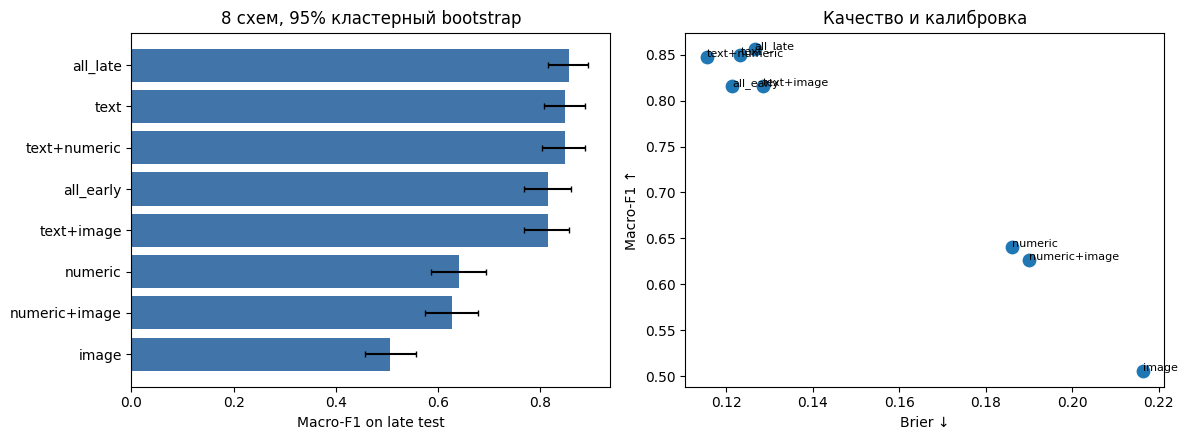

SUMMARY_JSON
{
  "gpu": "Tesla T4",
  "dataset_revision": "749931181c9cdd70bfa6408d8fe8b4ddd6107248",
  "n": {
    "train": 1200,
    "val": 300,
    "test": 400
  },
  "best_unimodal": "text",
  "best_fusion": "all_late",
  "selected": "text",
  "fusion_accepted": false,
  "delta_test_macro_f1": 0.0071419700524957275,
  "delta_ci95": [
    -0.011616249797708473,
    0.028124684715655584
  ],
  "permutation_p": 0.27472527472527475,
  "late_weights_TNI": [
    0.9,
    0.1,
    0.0
  ],
  "drift": {
    "train_negative_share": 0.21833333333333332,
    "test_negative_share": 0.3,
    "text_length_psi": 0.050112316560590474,
    "prior_mean_psi": 0.09754218782721139
  },
  "selected_test": {
    "macro_f1": 0.849313067478531,
    "auroc": 0.9477678571428572,
    "brier": 0.123292139872839,
    "ece": 0.1467965326474262,
    "recall_neg": 0.7416666666666667,
    "fn_per_1000": 77.5,
    "fp_per_1000": 45.0,
    "weighted_loss_per_1000": 432.5,
    "tn": 262,
    "fp": 18,
    "fn": 31,
   

In [12]:
import matplotlib.pyplot as plt
out=Path("/content/lab2_results"); out.mkdir(exist_ok=True)
comparison.to_csv(out/"model_comparison.csv",index=False)
ablation.to_csv(out/"ablation.csv",index=False)
error_rating.to_csv(out/"error_by_rating.csv")
error_len.to_csv(out/"error_by_length.csv")
audit["dataset_revision"]=REV
audit["split_time_ms"]={"train_val":float(q70),"val_test":float(q85)}
audit["split_dates"]={s:[str(x.date_utc.min()),str(x.date_utc.max())] for s,x in parts.items()}
audit["negative_share"]={s:float(x.y.mean()) for s,x in parts.items()}
(out/"data_audit.json").write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding="utf-8")
summary={"gpu":GPU,"dataset_revision":REV,"n":{s:len(x) for s,x in parts.items()},
         "best_unimodal":best_uni,"best_fusion":best_fusion,"selected":selected,
         "fusion_accepted":fusion_accepted,"delta_test_macro_f1":float(observed),
         "delta_ci95":delta_ci.tolist(),"permutation_p":float(p_value),
         "late_weights_TNI":late_weights.tolist(),"drift":drift,
         "selected_test":score(Y["test"],probs[selected]["test"],thresholds[selected]),
         "text_test":score(Y["test"],probs["text"]["test"],thresholds["text"]),
         "image_feature_ms":float(image_ms),"text_feature_ms":float(text_ms),
         "image_feature_total_seconds":float(image_seconds),"image_download_seconds":float(download_seconds)}
(out/"summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
plot=comparison.sort_values("macro_f1")
axes[0].barh(plot.scheme,plot.macro_f1,color="#4174a8")
axes[0].errorbar(plot.macro_f1,range(len(plot)),
                 xerr=[plot.macro_f1-plot.f1_ci_low,plot.f1_ci_high-plot.macro_f1],
                 fmt="none",ecolor="black",capsize=2)
axes[0].set(xlabel="Macro-F1 on late test",title="8 схем, 95% кластерный bootstrap")
axes[1].scatter(comparison.brier,comparison.macro_f1,s=80)
for r in comparison.itertuples(): axes[1].annotate(r.scheme,(r.brier,r.macro_f1),fontsize=8)
axes[1].set(xlabel="Brier ↓",ylabel="Macro-F1 ↑",title="Качество и калибровка")
fig.tight_layout(); fig.savefig(out/"models.png",dpi=150); plt.show()
print("SUMMARY_JSON")
print(json.dumps(summary,ensure_ascii=False,indent=2))
print("FILES:",[x.name for x in out.iterdir()])